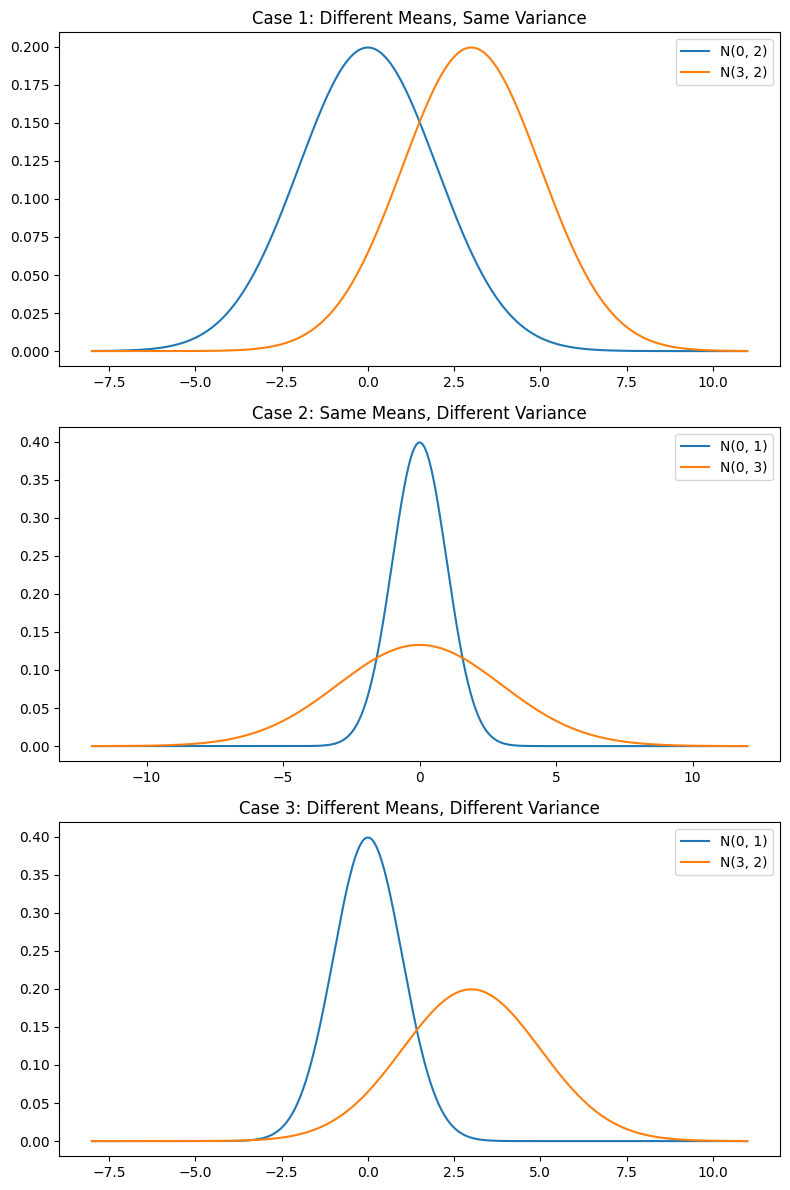

In [1]:
# 10.6 파이썬 실습
# 10.6.1 연속확률분포의 시각화
# 정규분포
#
import numpy as np
import matplotlib.pyplot as plt
# Define parameters for the normal distributions
# Case 1: Different means, same variance
mu_1_case1, sigma_1_case1 = 0, 2
mu_2_case1, sigma_2_case1 = 3, 2
# Case 2: Same means, different variance
mu_1_case2, sigma_1_case2 = 0, 1
mu_2_case2, sigma_2_case2 = 0, 3
# Case 3: Different means, different variance
mu_1_case3, sigma_1_case3 = 0, 1
mu_2_case3, sigma_2_case3 = 3, 2
# Function to plot normal distributions
def plot_normal_distributions(mu1, sigma1, mu2, sigma2, ax, title):
    x = np.linspace(min(mu1, mu2) - 4*max(sigma1, sigma2), max(mu1, mu2) + 4*max(sigma1, sigma2), 1000)
    y1 = (1 / (np.sqrt(2 * np.pi * sigma1**2))) * np.exp(-0.5 * ((x - mu1)**2) / sigma1**2)
    y2 = (1 / (np.sqrt(2 * np.pi * sigma2**2))) * np.exp(-0.5 * ((x - mu2)**2) / sigma2**2)

    ax.plot(x, y1, label=f'N({mu1}, {sigma1})')
    ax.plot(x, y2, label=f'N({mu2}, {sigma2})')
    ax.set_title(title)
    ax.legend()
# Create a figure with subplots
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
# Plot each case
plot_normal_distributions(mu_1_case1, sigma_1_case1, mu_2_case1, sigma_2_case1, axes[0], "Case 1: Different Means, Same Variance")
plot_normal_distributions(mu_1_case2, sigma_1_case2, mu_2_case2, sigma_2_case2, axes[1], "Case 2: Same Means, Different Variance")
plot_normal_distributions(mu_1_case3, sigma_1_case3, mu_2_case3, sigma_2_case3, axes[2], "Case 3: Different Means, Different Variance")
plt.tight_layout()
plt.show()


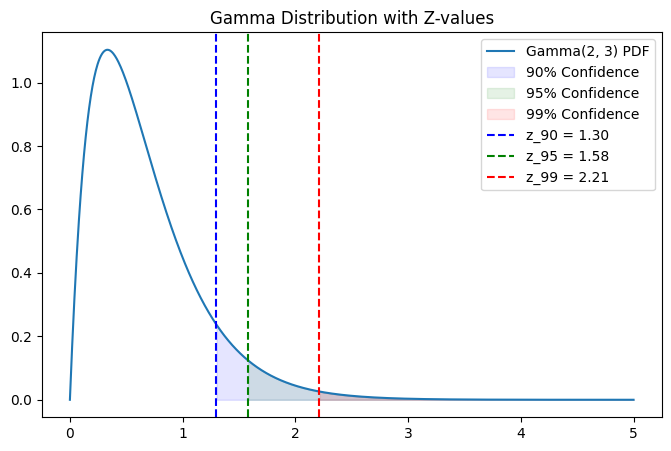

In [2]:
# 10.6 파이썬 실습
# 10.6.1 연속확률분포의 시각화
# 감마분포
#
from scipy.stats import gamma
# Parameters for the gamma distribution
alpha, beta = 2, 3
# Create a range of x values
x = np.linspace(0, 5, 1000)
# Calculate the PDF of the gamma distribution
y = gamma.pdf(x, a=alpha, scale=1/beta)
# Calculate z-values for the 90%, 95%, and 99% confidence levels
z_90 = gamma.ppf(0.90, a=alpha, scale=1/beta)
z_95 = gamma.ppf(0.95, a=alpha, scale=1/beta)
z_99 = gamma.ppf(0.99, a=alpha, scale=1/beta)
# Plotting
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y, label='Gamma(2, 3) PDF')
ax.fill_between(x, 0, y, where=(x >= z_90), color='blue', alpha=0.1, label='90% Confidence')
ax.fill_between(x, 0, y, where=(x >= z_95), color='green', alpha=0.1, label='95% Confidence')
ax.fill_between(x, 0, y, where=(x >= z_99), color='red', alpha=0.1, label='99% Confidence')
ax.axvline(z_90, color='blue', linestyle='--', label=f'z_90 = {z_90:.2f}')
ax.axvline(z_95, color='green', linestyle='--', label=f'z_95 = {z_95:.2f}')
ax.axvline(z_99, color='red', linestyle='--', label=f'z_99 = {z_99:.2f}')
ax.set_title('Gamma Distribution with Z-values')
ax.legend()
plt.show()

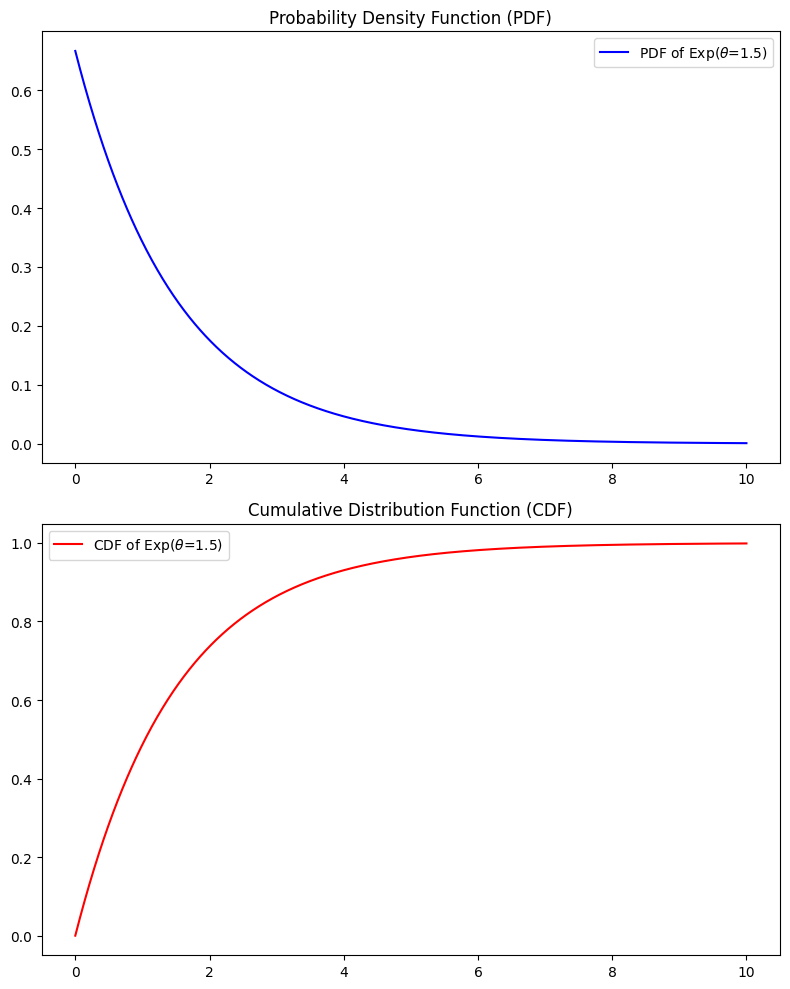

In [3]:
# 10.6 파이썬 실습
# 10.6.1 연속확률분포의 시각화
# 지수분포
#
# Import the necessary module
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import expon
# Parameters for the exponential distribution
theta = 1.5  # mean and variance theta^2
# Create a range of x values
x = np.linspace(0, 10, 1000)
# Calculate the PDF and CDF of the exponential distribution
pdf = expon.pdf(x, scale=theta)
cdf = expon.cdf(x, scale=theta)
# Plotting PDF and CDF
fig, ax = plt.subplots(2, 1, figsize=(8, 10))
# PDF
ax[0].plot(x, pdf, 'b-', label=f'PDF of Exp($\\theta$={theta})')
ax[0].set_title('Probability Density Function (PDF)')
ax[0].legend()
# CDF
ax[1].plot(x, cdf, 'r-', label=f'CDF of Exp($\\theta$={theta})')
ax[1].set_title('Cumulative Distribution Function (CDF)')
ax[1].legend()
plt.tight_layout()
plt.show()

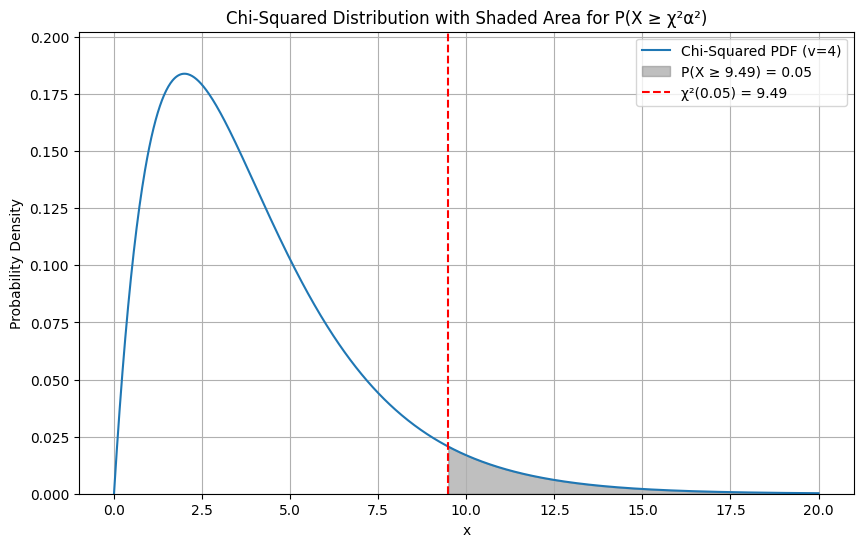

In [4]:
# 10.6 파이썬 실습
# 10.6.1 연속확률분포의 시각화
# 자유도가 4인 카이제곱 분포
#
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
# Set the degree of freedom
df = 4
# Define the alpha value for the right-tail probability
alpha = 0.05
# Calculate the chi-squared value at which P(X >= chi2_alpha^2) = alpha
chi2_alpha_squared = chi2.ppf(1 - alpha, df)
# Define the range of x values for plotting
x_chi2 = np.linspace(0, 20, 1000)
# Calculate the PDF values for the chi-squared distribution
y_chi2 = chi2.pdf(x_chi2, df)
# Plotting
plt.figure(figsize=(10, 6))
plt.plot(x_chi2, y_chi2, label=f'Chi-Squared PDF (v={df})')
plt.fill_between(x_chi2, 0, y_chi2, where=(x_chi2 >= chi2_alpha_squared), color='grey', alpha=0.5, label=f'P(X ≥ {chi2_alpha_squared:.2f}) = {alpha}')
plt.axvline(x=chi2_alpha_squared, color='red', linestyle='--', label=f'χ²({alpha}) = {chi2_alpha_squared:.2f}')
plt.ylim(0, max(y_chi2) * 1.1)  # Adjust y-axis to make sure everything fits nicely
plt.title('Chi-Squared Distribution with Shaded Area for P(X ≥ χ²α²)')
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True)
plt.show()